In [2]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np

In [126]:
import numpy as np



group_std_list = []

for i in range(0, len(data), 5):
    group = data[i:i+5]
    std = np.std(group, ddof=1)  # 样本标准差
    mean = np.mean(group)
    group_std_list.append(std)
    group_std_list.append(mean)
    
# for idx, std ,mean in enumerate(group_std_list, 2):
#     print(f"Group {idx}: Std = {std:.6f}, mean {mean}")
std = group_std_list[0::2]
mean = group_std_list[1::2]
np.array(std)*100

array([7.09873963, 3.78385432, 4.51224605, 4.3268484 , 2.58074951,
       1.84318336, 0.81663002, 1.1043871 , 0.68839355])

In [ ]:
mean = [55.036694, 42.223576,36.7385427 ,34.6383776 ,32.560794 ,30.346156 ,31.3839946 ,28.6352592 ,28.2111145]
mean2 = [60.2723735, 47.0139939 ,42.1465425,39.2251742,34.6998509,33.9859012,33.6577571,31.5111054,30.7241485]

MSE = []


In [293]:
RMSE_mean_4 =  [55.036694, 42.223576,36.7385427 ,34.6383776 ,32.560794 ,30.346156 ,31.3839946 ,28.6352592 ,28.2111145, 27.1022]
RMSE_mean_1 = [60.2723735, 47.0139939 ,42.1465425,39.2251742,34.6998509,33.9859012,33.6577571,31.5111054,30.7241485, 28.60776]
dif_rmse = np.array(MAE_mean_1) - np.array(MAE_mean_4)
dif_rmse

array([5.85625398, 4.3971302 , 4.7050355 , 4.35223216, 2.09759278,
       2.69318376, 1.78930854, 2.5491887 , 2.19066368, 1.226112  ])

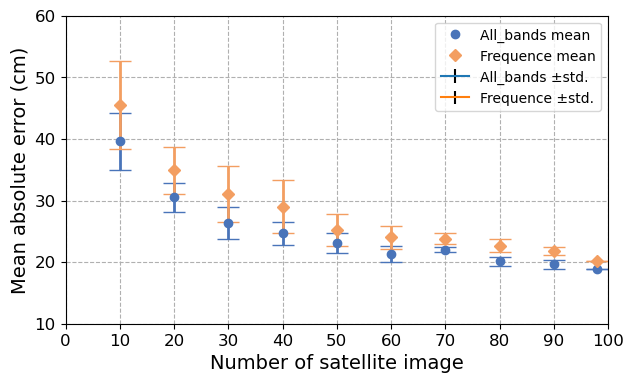

In [184]:
import numpy as np
import matplotlib.pyplot as plt

# 示例数据（可以替换为你的实际数据）
x = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 98])# 比如距离或序号，共30个点
RMSE_mean_4 =  [55.036694, 42.223576,36.7385427 ,34.6383776 ,32.560794 ,30.346156 ,31.3839946 ,28.6352592 ,28.2111145, 27.1022]
RMSE_std_4 = [4.9548, 2.7322, 2.9617, 1.6623, 1.6646, 0.7560, 0.3878, 0.3693, 0.06948, 0]   # 示例标准差，越往后越小
RMSE_mean_1 = [60.2723735, 47.0139939 ,42.1465425,39.2251742,34.6998509,33.9859012,33.6577571,31.5111054,30.7241485, 28.60776]
RMSE_std_1 = [6.7986, 3.3723, 5.2772, 3.8250, 2.4081, 1.6942, 0.8016, 0.3702, 0.5692, 0]

MAE_mean_4 = [39.62577496, 30.52165152, 26.36437116, 24.65639346, 23.07232366, 21.30581506, 22.04370636, 20.13424844, 19.62520486, 18.87493]
MAE_std_4 = [4.65989233, 2.36769773, 2.5634239 , 1.86823426, 1.61662801, 1.2601519 , 0.36651237, 0.76212813, 0.7135867, 0 ]
MAE_mean_1 = [45.48202894, 34.91878172, 31.06940666, 29.00862562, 25.16991644, 23.99899882, 23.8330149 , 22.68343714, 21.815868541, 20.101042]
MAE_std_1 = [7.09873963, 3.78385432, 4.51224605, 4.3268484 , 2.58074951, 1.84318336, 0.81663002, 1.1043871 , 0.68839355, 0]
# 绘图
fig, ax = plt.subplots(figsize=(7, 4))

# 绘制误差棒图（上下误差相等）
ax.errorbar(x, MAE_mean_4, yerr=MAE_std_4, fmt='o', color="#4974B9FF", ecolor="#4974B9FF", capsize=8, linewidth=2)
ax.errorbar(x, MAE_mean_1, yerr=MAE_std_1, fmt='D', color="#F39E61", ecolor="#F39E61", capsize=8, elinewidth=2, linewidth=2)
# 添加 ±0.24 m 的参考线
# ax.axhline(y=20, linestyle='--', color='gray')
# ax.axhline(y=70, linestyle='--', color='gray')

# 添加零线（更粗）
ax.axhline(y=0, linestyle='-', color='gray', linewidth=10, alpha=0.3)

# 图例
ax.plot([], [], 'o',  color="#4974B9FF", markeredgecolor='#4974B9FF', label='All_bands mean')
ax.plot([], [], 'D',  color="#F39E61", markeredgecolor='#F39E61', label='Frequence mean')

ax.errorbar([], [], yerr=[[0.5], [0.5]], fmt='', ecolor='black', capsize=5, label='All_bands ±std.')
ax.errorbar([], [], yerr=[[0.1], [0.1]], fmt='', ecolor='black', capsize=5, label='Frequence ±std.')
ax.legend(frameon=True)

ax.grid(axis='x', linestyle='--', alpha=1)
ax.grid(axis='y', linestyle='--', alpha=1)
ax.grid(True)

# 标签与样式
ax.tick_params(axis='both', labelsize=12)
# ax.set_ylabel('Root mean square error (cm)', fontsize=14)
ax.set_ylabel('Mean absolute error (cm)', fontsize=14)
ax.set_xlabel('Number of satellite image', fontsize=14)
# ax.set_ylim(20, 70)
plt.xlim(0, 100)
plt.xticks(np.arange(0, 101, 10))
ax.set_ylim(10, 60)
# ax.set_xlim(0, 100)
# plt.tight_layout()
plt.show()


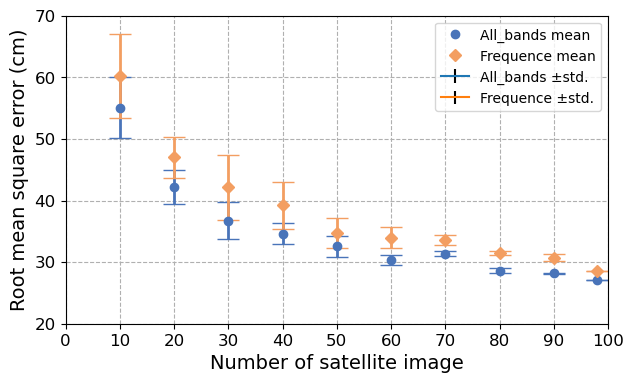

In [183]:
import numpy as np
import matplotlib.pyplot as plt

# 示例数据（可以替换为你的实际数据）
x = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 98])# 比如距离或序号，共30个点
RMSE_mean_4 =  [55.036694, 42.223576,36.7385427 ,34.6383776 ,32.560794 ,30.346156 ,31.3839946 ,28.6352592 ,28.2111145, 27.1022]
RMSE_std_4 = [4.9548, 2.7322, 2.9617, 1.6623, 1.6646, 0.7560, 0.3878, 0.3693, 0.06948, 0]   # 示例标准差，越往后越小
RMSE_mean_1 = [60.2723735, 47.0139939 ,42.1465425,39.2251742,34.6998509,33.9859012,33.6577571,31.5111054,30.7241485, 28.60776]
RMSE_std_1 = [6.7986, 3.3723, 5.2772, 3.8250, 2.4081, 1.6942, 0.8016, 0.3702, 0.5692, 0]

MAE_mean_4 = [39.62577496, 30.52165152, 26.36437116, 24.65639346, 23.07232366, 21.30581506, 22.04370636, 20.13424844, 19.62520486, 18.87493]
MAE_std_4 = [4.65989233, 2.36769773, 2.5634239 , 1.86823426, 1.61662801, 1.2601519 , 0.36651237, 0.76212813, 0.7135867, 0 ]
MAE_mean_1 = [45.48202894, 34.91878172, 31.06940666, 29.00862562, 25.16991644, 23.99899882, 23.8330149 , 22.68343714, 21.815868541, 20.101042]
MAE_std_1 = [7.09873963, 3.78385432, 4.51224605, 4.3268484 , 2.58074951, 1.84318336, 0.81663002, 1.1043871 , 0.68839355, 0]
# 绘图
fig, ax = plt.subplots(figsize=(7, 4))

# 绘制误差棒图（上下误差相等）
ax.errorbar(x, RMSE_mean_4, yerr=RMSE_std_4, fmt='o', color="#4974B9FF", ecolor="#4974B9FF", capsize=8, linewidth=2)
ax.errorbar(x, RMSE_mean_1, yerr=RMSE_std_1, fmt='D', color="#F39E61", ecolor="#F39E61", capsize=8, elinewidth=2, linewidth=2)
# 添加 ±0.24 m 的参考线
# ax.axhline(y=20, linestyle='--', color='gray')
# ax.axhline(y=70, linestyle='--', color='gray')

# 添加零线（更粗）
ax.axhline(y=0, linestyle='-', color='gray', linewidth=10, alpha=0.3)

# 图例
ax.plot([], [], 'o',  color="#4974B9FF", markeredgecolor='#4974B9FF', label='All_bands mean')
ax.plot([], [], 'D',  color="#F39E61", markeredgecolor='#F39E61', label='Frequence mean')

ax.errorbar([], [], yerr=[[0.5], [0.5]], fmt='', ecolor='black', capsize=5, label='All_bands ±std.')
ax.errorbar([], [], yerr=[[0.1], [0.1]], fmt='', ecolor='black', capsize=5, label='Frequence ±std.')
ax.legend(frameon=True)

ax.grid(axis='x', linestyle='--', alpha=1)
ax.grid(axis='y', linestyle='--', alpha=1)
ax.grid(True)

# 标签与样式
ax.tick_params(axis='both', labelsize=12)
ax.set_ylabel('Root mean square error (cm)', fontsize=14)
#ax.set_ylabel('Mean absolute error (cm)', fontsize=14)
ax.set_xlabel('Number of satellite image', fontsize=14)
ax.set_ylim(20, 70)
plt.xlim(0, 100)
plt.xticks(np.arange(0, 101, 10))
# ax.set_ylim(10, 60)
# ax.set_xlim(0, 100)
# plt.tight_layout()
plt.show()


In [3]:

region = 'Region4'
location = 'Severn'
location2 = 'Severn'
method = 'RF'
Bands = 4
year = 2020

ref_dem_path = f"G:\DTM_ref\{location2}\{location2}_{year}\{location2}_masked_{year}.tif"
# ref_dem_path = 'G:\DTM_ref\Carmarthen\Carmarthen_2021\Carmarthen_masked_2021.tif'
retrieved_dem_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_{Bands}_{method}_FB6_new10_AAA.tif"
validation_sample_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points.shp'
validation_sample_csv_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points.csv'

#-------------------------------------------------------
# ref_dem_path = f"G:\ICESat-2\Discussion5_1\DTM_refer/Severn_masked_2020.tif"
# retrieved_dem_path = f'G:\ICESat-2\Discussion5_1\Retrival_DTM\{location}_{year}_4_{method}_FB6_new10.tif'
# validation_sample_path = f'G:\ICESat-2\Discussion5_1\ICESAT/Ref_{location}_{year}_sample_points.shp'
# validation_sample_csv_path = f'G:\ICESat-2\Discussion5_1\ICESAT/Ref_{location}_{year}_sample_points.csv'

#-------------------------------------------------------

# 打开两个 raster
with rasterio.open(ref_dem_path) as src1, rasterio.open(retrieved_dem_path) as src2:
    # 计算交集区域（bounding box）
    bounds1 = src1.bounds
    bounds2 = src2.bounds

    intersection = box(
        max(bounds1.left, bounds2.left),
        max(bounds1.bottom, bounds2.bottom),
        min(bounds1.right, bounds2.right),
        min(bounds1.top, bounds2.top)
    )

    if intersection.is_empty:
        raise ValueError("两个 raster 没有空间交集")

    # 统一坐标系（假设两个 raster 已经在同一坐标系，否则需要 reproject）

    # 设置目标分辨率与 shape
    res = 30
    width = int((intersection.bounds[2] - intersection.bounds[0]) / res)
    height = int((intersection.bounds[3] - intersection.bounds[1]) / res)
    transform = from_origin(intersection.bounds[0], intersection.bounds[3], res, res)

    # 重采样并裁剪两个 raster 到相同区域和分辨率
    def reproject_to_common(src):
        dst_array = np.empty((height, width), dtype=src.read(1).dtype)
        reproject(
            source=rasterio.band(src, 1),
            destination=dst_array,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=transform,
            dst_crs=src.crs,
            resampling=Resampling.nearest
        )
        return dst_array

    data1 = reproject_to_common(src1)
    data2 = reproject_to_common(src2)
    crs = src1.crs

# 创建有效掩膜
mask1 = (data1 != src1.nodata) & (data1 != 6) & (data1 != 0)
mask2 = (data2 != src2.nodata) & (data2 != 0)
valid_mask = mask1 & mask2

valid_indices = np.argwhere(valid_mask)

if len(valid_indices) == 0:
    raise ValueError("没有满足条件的像元")

# 随机抽样点
n_points = int(len(valid_indices)/30)
sampled_indices = valid_indices[np.random.choice(len(valid_indices), n_points, replace=False)]

points = []
vals1 = []
vals2 = []

for row, col in sampled_indices:
    x, y = transform * (col + 0.5, row + 0.5)
    points.append(Point(x, y))
    vals1.append(data1[row, col])
    vals2.append(data2[row, col])

gdf = gpd.GeoDataFrame({
    'Refer_dem': vals1,
    'retrieved_dem': vals2
}, geometry=points, crs=crs)

# 保存结果
gdf.to_file(validation_sample_path)
gdf.to_csv(validation_sample_csv_path)

C:\Users\minyu\AppData\Local\Temp\ipykernel_10400\836519562.py:94: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf.to_file(validation_sample_path)
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'retrieved_dem' to 'retrieved_'
  ogr_write(


In [44]:
path = 'G:\ICESat-2\Discussion5_1\Validation_point\wash_bay_2022_sample_points.shp'
z = gpd.read_file(path)
z.columns

Index(['Refer_dem', 'retrieved_', 'RF2', 'RF1', 'RF', 'RF3', 'RW1_dtm',
       'RF_raw', 'RW2_dtm', 'DTM_1_RF', 'DTM_2_RF', 'DTM_3_RF', 'DTM_4_RF',
       'DTM_RF_20', 'DTM_RF_40', 'DTM_RF_60', 'DTM_RF_80', 'DTM_Linear',
       'DTM_Poly', 'D1924_4_', 'D1924_1_', 'wash_4_97', 'wash_4_90',
       'wash_4_80', 'wash_4_70', 'wash_4_60', 'wash_4_50', 'wash_4_40',
       'wash_4_30', 'wash_4_20', 'wash_4_10', 'Wash_1_97', 'Wash_1_90',
       'Wash_1_80', 'Wash_1_70', 'Wash_1_60', 'Wash_1_50', 'Wash_1_40',
       'Wash_1_30', 'Wash_1_20', 'Wash_1_10', 'geometry'],
      dtype='object')

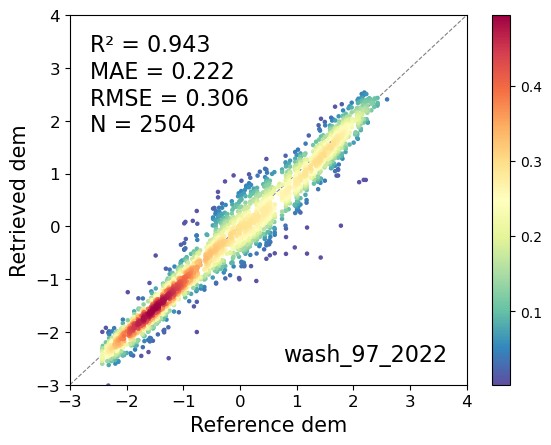

In [58]:
path = 'G:\ICESat-2\Discussion5_1\Validation_point\wash_bay_2022_sample_points.shp'
z = gpd.read_file(path)
z.columns
z = z[z!=0]
z = z.dropna()

obs_num  = 97
x = z['Refer_dem']
y = z[f'Wash_1_{obs_num}']
y = np.array(y)
x = np.array(x)

R, _ = pearsonr(y, x)
R2 = r2_score(y, x)
MAD = np.mean(np.abs(y-x))
MSB = np.mean((y-x))
RMSE = np.sqrt(np.mean((y-x)**2))
num = int(len(x))


xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

# Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R2:.3f}\nMAE = {MAD:.3f}\nRMSE = {RMSE:.3f} \nN = {num}"
# name = f'{'Wash'} ({year})'
name = f'wash_{obs_num}_2022'
ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

ax.set_xlabel('Reference dem', fontsize = 15)
ax.set_ylabel('Retrieved dem', fontsize = 15)
ax.plot([-3, 4], [-3, 4], color='gray', linestyle='--', linewidth=0.8, zorder=1)
sc = plt.scatter(y, x, c=z, s=5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)

# plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
# plt.colorbar()

ax.set_xlim(-3, 4)
ax.set_ylim(-3, 4)
ax.tick_params(axis='both', labelsize=12)
output_path = f"G:\ICESat-2\Discussion5_2\graph/wash_{obs_num}_Freq_2022.png"  # 例如："./output/plot.png"
plt.savefig(output_path, dpi=300, bbox_inches='tight') 
plt.show()


In [30]:

region = 'Region4'
location = 'Ribble'
location2 = 'Ribble'
year = 2023
# 路径
shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp"
output_shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp"
output_csv_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.csv"
#raster_path = f"G:\DTM_ref\{location}\{location}_{year}\{location}_masked_{year}.tif"
raster_path = f"G:\DTM_ref\{location2}\{location2}_{year}\{location2}_masked_{year}.tif"
# 1. 读取 shp 点数据
points = gpd.read_file(shp_path)

# 2. 打开栅格数据
with rasterio.open(raster_path) as src:
    raster_crs = src.crs  # 获取 raster 的坐标系
    
    # 3. 如果坐标系不同，则重投影点数据
    if points.crs != raster_crs:
       # print(f"坐标系不一致，正在从 {points.crs} 转换为 {raster_crs}")
        points = points.to_crs(raster_crs)

    # 4. 获取坐标并提取像元值（默认波段 1）
    coords = [(geom.x, geom.y) for geom in points.geometry]
    values = [val[0] for val in src.sample(coords)]

# 5. 将像元值添加到 GeoDataFrame 中
points['raster_val'] = values

# 6. 保存结果
points.to_file(output_shp_path)
points[['geometry', 'raster_val', 'OH']].to_csv(output_csv_path, index=False)

print("提取完成 ✅")


提取完成 ✅


In [ ]:
#------------------------For ICESat Point validation------------------------------------


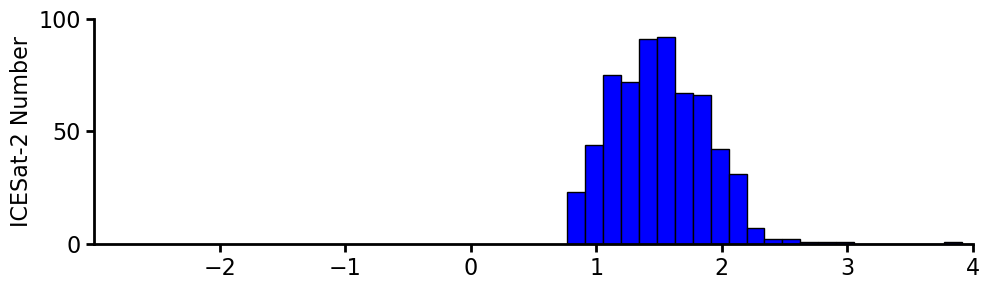

In [3]:
import matplotlib.pyplot as plt
import numpy as np

import pandas as pd
region = 'Region2'
year = 2021
location = 'wash_bay'

csv_path = f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10.shp'
z = gpd.read_file(csv_path)
z = pd.DataFrame(z)
z['OH']

data = np.array(z['OH'])

# 绘制直方图
plt.figure(figsize=(10, 3))
plt.hist(data, bins=25, color="blue", edgecolor="black")

# 设置坐标轴范围和标签
plt.ylim(0, 100)
plt.yticks(np.arange(0, 101, 50))

plt.xlim(-3, 4)
plt.xticks(np.arange(-2, 5, 1))

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# plt.xlabel('Height value', fontsize=16)
plt.ylabel('ICESat-2 Number', fontsize=16)

# ✅ 获取当前坐标轴对象，并去除右侧和上方边框
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

# ✅ 加粗刻度线
ax.tick_params(width=2, length=6)

plt.tight_layout()
plt.show()


In [4]:
plt.figure(figsize=(8, 2))
plt.hist(Z_half, bins=100, edgecolor='white', alpha=0.8, color='red')  # 转换为 numpy 并设置 50 个 bins
plt.xlabel('Height')
plt.ylabel('Number')
plt.title('Histogram of ICESat-2 in Wash bay(2022)')
plt.xlim(-3, 5)
plt.ylim(0,50)
plt.show()

NameError: name 'Z_half' is not defined

<Figure size 800x200 with 0 Axes>

In [119]:
import geopandas as gpd
import rasterio
from rasterio.sample import sample_gen

import numpy as np
import pandas as pd
import rioxarray as rxr
from osgeo import gdal
import rasterio
from shapely.geometry import box
import pandas as pd
from shapely.geometry import Point
from rasterio.sample import sample_gen
import geopandas as gpd


# 读取 Shapefile（点数据）
shp_path = 'G:\ICESat-2\Region2_map\wash_bay_map\A2022\A_wash_bay_30m_2022.shp' # 替换为你的 .shp 文件路径
shp_path = 'G:\ICESat-2\Region1_map\Thames_map\A2022\A_Thames_30m_2022.shp'
shp_path = 'F:\ICESat-2\Region4_map\Ribble_map\A2022\A_Ribble_30m_2022_r.shp'
shp_path = 'F:\ICESat-2\Region4_map\Morecambe_map\A2022\A_Morecambe_30m_2022_r.shp'
shp_path = 'G:\ICESat-2\Region1_map\Thames_map\A2022\A_Thames_30m_2022_r.shp'
shp_path = 'G:\ICESat-2\Region1\Region1_Thames\A2019\A_Thames_30m_2019_c.shp'
shp_path = 'F:\ICESat-2\Region4_map\Morecambe_map\A2019\A_Morecambe_30m_2019.shp'
# shp_path = 'F:\ICESat-2\Region4_map\Solway_map\A2022\A_Solway_30m_2022.shp'
shp_path = 'G:\ICESat-2\Region1_map\Thames_map\A2022\Validation_2022_wash.shp'
gdf = gpd.read_file(shp_path, engine="fiona")
gdf.head()
# 读取单波段 raster 影像


# # #raster_path = 'G:\DTM/UK_br_left_2022_dtm_30.tif'#UK_left_2022_dtm_30.tif'#UK_m_2022_dtm_30.tif'
# raster_path = 'G:\DTM_ref\Thames_2019\DTM_merge/Thames_2019_merge_p.tif'
# with rasterio.open(raster_path) as src:#
#     # 获取点的坐标
#     # if points.crs != src.crs:
#     #     points = points.to_crs(src.crs)
#     coords = [(x, y) for x, y in zip(gdf.geometry.x, gdf.geometry.y)]
    
#     # 采样像元值
#     values = list(src.sample(coords))
    
#     # 由于 sample() 返回的是嵌套列表（[[val1], [val2], ...]），我们需要解包
#     gdf["raster_value"] = [v[0] for v in values]

# # 查看结果
# print(gdf.head())

# gdf = gpd.read_file(shp_path, engine="fiona")
# gdf

,Value_Imag,Value_Im_1,Thames_19,R_Tha_19,geometry
0,0.107170,0.135781,0.145170,0.05250,POINT (770505 5719725)
1,-0.769911,-1.185234,-0.774275,-0.69750,POINT (769095 5714685)
2,0.633915,0.426448,0.516142,0.60025,POINT (742335 5709825)
3,0.403761,0.539574,0.420215,0.49750,POINT (768585 5718675)
4,0.303836,0.389660,0.320929,0.35500,POINT (768585 5718525)


(1759, 5)


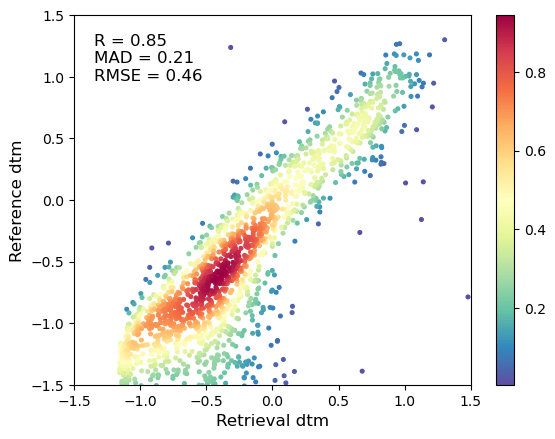

In [ ]:
mask = (gdf['R_Tha_19']> -10) & (gdf['Thames_19']> -10) & (gdf['Thames_19'] != 0)
k = gdf[mask]
print(k.shape)
x = k['Thames_19']
y = k['R_Tha_19']
y = np.array(y)
x = np.array(x)

R, _ = pearsonr(x, y)
MAD = np.median(np.abs(y-x))
RMSE = np.sqrt(np.mean((y-x)**2))


xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

# Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R = {R:.2f}\nMAD = {MAD:.2f}\nRMSE = {RMSE:.2f}"
ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 12, verticalalignment = 'top')

ax.set_ylabel('Reference dem', fontsize = 12)
ax.set_xlabel('ICESat-2 point', fontsize = 12)
# ax.set_ylabel('Reference dtm', fontsize = 12)
# ax.set_xlabel('Retrieval dtm', fontsize = 12)
plt.scatter(x, y,c=z, s=7,cmap='Spectral_r') # c表示标记的颜色
plt.colorbar()
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
plt.show()

In [ ]:
#------------------------for images validation-----------------------
import rasterio
import numpy as np
import random

# 读取影像

raster_path = 'G:\ICESat-2\Region2_map\wash_bay_map\A2022\wash_bay_2022_4_RF_FB6z.tif'
ref_path = 'G:\DTM/UK_m_2022_dtm_30.tif'


with rasterio.open(raster_path) as src:
    image = src.read(1)  # 读取第一波段
    transform = src.transform  # 获取地理坐标转换参数


# 找到值 > 0 的像素索引
valid_pixels = np.column_stack(np.where(image > 0))  # 行、列索引

# 随机选择 N 个点
N = 100  # 需要的随机点数
random_indices = random.sample(range(len(valid_pixels)), min(N, len(valid_pixels)))
selected_pixels = valid_pixels[random_indices]

# 转换为地理坐标
sample_points = [rasterio.transform.xy(transform, row, col) for row, col in selected_pixels]
# print(sample_points)
# # 提取影像特征值
# z = gpd.GeoDataFrame(sample_points)
# print(z)
# with rasterio.open(ref_path) as src:
#     coords = [(z.x)]


sample_values = [image[row, col] for row, col in selected_pixels]
df.to_csv("random_points_values.csv", index=False)
# 打印部分结果
#for point, value in zip(sample_points[:5], sample_values[:5]):  # 只显示前5个
    # print(f"coods: {point}, 特征值: {value}")


In [8]:
import rasterio
from rasterio.warp import reproject, Resampling
import numpy as np
import random
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

# 影像文件路径
# raster1_path = 'G:\ICESat-2\Region2_map\wash_bay_map\A2022\wash_bay_2022_4_RF_FB6z.tif'  # 第一幅影像（参考影像）
# raster1_path = 'G:\ICESat-2\Region1_map\Thames_map\A2019\Thames_2019_4_RF_FB6.tif'
raster1_path = 'G:\ICESat-2\Discussion5_1\Retrival_DTM\Ribble_c_2022_4_RF_FB6_new10.tif'

raster2_path = 'G:\ICESat-2\Discussion5_1\DTM_refer/ribble_masked_2022.tif' 
# raster2_path = 'G:\DTM_ref\Thames_2019\DTM_merge\Thames_2019_merge_p.tif'
#output_shapefile = "G:\DTM/random_points.shp"  # 输出点文件

output_shapefile = 'G:\ICESat-2\Discussion5_1\Validation_point\Validation_2022_Ribble.shp'

# 读取第一幅影像（参考影像）
with rasterio.open(raster1_path) as src1:
    image1 = src1.read(1)  # 读取第一波段
    transform1 = src1.transform  # 获取地理坐标转换参数
    crs1 = src1.crs  # 坐标系
    shape1 = src1.shape  # 影像 shape（行, 列）

# 读取第二幅影像
with rasterio.open(raster2_path) as src2:
    image2 = src2.read(1)  # 读取第一波段
    transform2 = src2.transform  # 原始地理变换
    crs2 = src2.crs  # 坐标系
    shape2 = src2.shape  # 影像 shape

# 如果两幅影像的坐标系不同，则重投影影像2
if crs1 != crs2:
    print("坐标系不匹配，正在重投影影像2...")
    dst_image2 = np.empty(shape1, dtype=image2.dtype)
    
    reproject(
        source=image2,
        destination=dst_image2,
        src_transform=transform2,
        src_crs=crs2,
        dst_transform=transform1,
        dst_crs=crs1,
        resampling=Resampling.nearest  # 采用最近邻插值
    )
    image2 = dst_image2  # 更新为匹配影像1的重投影数据

# 找到值 > 0 的像素索引（只在第一幅影像中采样）
valid_pixels = np.column_stack(np.where((image1 != 0) & (image2 != 6) ))  # 行、列索引

# 随机选择 N 个点
N = int(len(valid_pixels)/50) # 采样点数量
random_indices = random.sample(range(len(valid_pixels)), min(N, len(valid_pixels)))
selected_pixels = valid_pixels[random_indices]

# 转换为地理坐标并提取影像值
point_list = []
for row, col in selected_pixels:
    lon, lat = rasterio.transform.xy(transform1, row, col)  # 转换为地理坐标
    value1 = image1[row, col]  # 第一幅影像值
    value2 = image2[row, col]  # 重采样后第二幅影像值
    point_list.append([Point(lon, lat), value1, value2])

# 创建 GeoDataFrame
gdf = gpd.GeoDataFrame(point_list, columns=["geometry", "Value_Image1", "Value_Image2"], crs=crs1)
print(gdf)
# 保存为 Shapefile

gdf.to_file(output_shapefile, driver="ESRI Shapefile",  engine="fiona")

print(f"Shapefile {output_shapefile} 已生成，包含 {len(gdf)} 个点")


ValueError: operands could not be broadcast together with shapes (942,813) (4616,2189) 

In [15]:
import rasterio
from rasterio.warp import reproject, Resampling
import numpy as np
import random
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

# 影像文件路径
raster1_path = 'G:\ICESat-2\Discussion5_1\Retrival_DTM\Ribble_c_2022_4_RF_FB6_new10.tif'  # 第一幅影像（参考影像）
raster2_path = 'G:\ICESat-2\Discussion5_1\DTM_refer/ribble_masked_2022.tif'               # 第二幅影像（需对齐）

output_shapefile = 'G:\ICESat-2\Discussion5_1\Validation_point\Validation_2022_Ribble1.shp'  # 输出点文件路径

# 读取第一幅影像
with rasterio.open(raster1_path) as src1:
    image1 = src1.read(1)
    transform1 = src1.transform
    crs1 = src1.crs
    shape1 = src1.shape

# 读取第二幅影像
with rasterio.open(raster2_path) as src2:
    image2 = src2.read(1)
    transform2 = src2.transform
    crs2 = src2.crs
    shape2 = src2.shape

# === 始终对 raster2 进行重投影 + 重采样，匹配 raster1 ===
print("正在重采样和重投影第二幅影像以匹配第一幅影像...")
dst_image2 = np.empty(shape1, dtype=image2.dtype)

reproject(
    source=image2,
    destination=dst_image2,
    src_transform=transform2,
    src_crs=crs2,
    dst_transform=transform1,
    dst_crs=crs1,
    resampling=Resampling.nearest
)

image2 = dst_image2  # 替换为对齐后的 image2

# 确保尺寸一致
assert image1.shape == image2.shape, f"Shape mismatch after alignment: {image1.shape} vs {image2.shape}"

# 选择满足条件的像素：image1 非零，image2 不等于 6
valid_pixels = np.column_stack(np.where((image1 != 0) & (image2 != 6) & (image2 != 0)))
print(f"找到 {len(valid_pixels)} 个有效像素点")

# 随机选择 N 个像素
N = int(len(valid_pixels) / 50)
random_indices = random.sample(range(len(valid_pixels)), min(N, len(valid_pixels)))
selected_pixels = valid_pixels[random_indices]

# 转换为地理坐标并提取影像值
point_list = []
for row, col in selected_pixels:
    lon, lat = rasterio.transform.xy(transform1, row, col)
    value1 = image1[row, col]
    value2 = image2[row, col]
    point_list.append([Point(lon, lat), value1, value2])

# 创建 GeoDataFrame
gdf = gpd.GeoDataFrame(point_list, columns=["geometry", "Value_Image1", "Ref_DTM"], crs=crs1)

# 输出信息
print(gdf.head())
print(f"准备保存 {len(gdf)} 个点到 {output_shapefile}")

# 保存为 shapefile
gdf.to_file(output_shapefile, driver="ESRI Shapefile", engine="fiona")

print(f"Shapefile 已成功保存：{output_shapefile}")


正在重采样和重投影第二幅影像以匹配第一幅影像...
找到 79067 个有效像素点
                 geometry  Value_Image1  Ref_DTM
0  POINT (501555 5951385)      1.885792    1.952
1  POINT (494805 5952885)     -2.459121   -2.474
2  POINT (496605 5953815)     -0.005500    0.114
3  POINT (498975 5954355)      3.545712    4.195
4  POINT (496635 5950125)     -0.806805   -0.969
准备保存 1581 个点到 G:\ICESat-2\Discussion5_1\Validation_point\Validation_2022_Ribble1.shp


C:\Users\minyu\AppData\Local\Temp\ipykernel_912\3399131984.py:73: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf.to_file(output_shapefile, driver="ESRI Shapefile", engine="fiona")


Shapefile 已成功保存：G:\ICESat-2\Discussion5_1\Validation_point\Validation_2022_Ribble1.shp


In [16]:
import rasterio
from rasterio.warp import reproject, Resampling, calculate_default_transform
import numpy as np

# 输入路径 & 输出路径
src_path = 'G:\ICESat-2\Discussion5_1\DTM_refer/ribble_masked_2022.tif'
dst_path = 'G:\ICESat-2\Discussion5_1\DTM_refer/ribble_masked_2022_resampled_30m.tif'

# 目标分辨率（30米）
target_resolution = 30

with rasterio.open(src_path) as src:
    src_data = src.read(1)
    src_transform = src.transform
    src_crs = src.crs
    src_dtype = src.dtypes[0]
    src_nodata = src.nodata

    # 计算新的 transform 和 shape（rows, cols）
    dst_transform, dst_width, dst_height = calculate_default_transform(
        src_crs, src_crs, src.width, src.height, *src.bounds, resolution=target_resolution
    )

    # 创建输出数组
    dst_data = np.empty((dst_height, dst_width), dtype=src_dtype)

    # 执行重采样
    reproject(
        source=src_data,
        destination=dst_data,
        src_transform=src_transform,
        src_crs=src_crs,
        dst_transform=dst_transform,
        dst_crs=src_crs,
        resampling=Resampling.nearest
    )

    # 写入输出文件
    profile = src.profile.copy()
    profile.update({
        'transform': dst_transform,
        'height': dst_height,
        'width': dst_width,
        'driver': 'GTiff',
        'nodata': src_nodata
    })

    with rasterio.open(dst_path, 'w', **profile) as dst:
        dst.write(dst_data, 1)

print(f"重采样完成，输出保存至：{dst_path}")


重采样完成，输出保存至：G:\ICESat-2\Discussion5_1\DTM_refer/ribble_masked_2022_resampled_30m.tif


In [ ]:
mask = (gdf['Value_Imag']> -10) & (gdf['Value_Im_1']> -10) & (gdf['Value_Im_1'] !=0)
k = gdf[mask]
print(k.shape)
x = k['Value_Im_1']
y = k['Value_Imag']
y = np.array(y)
x = np.array(x)

R, _ = pearsonr(x, y)
MAD = np.median(np.abs(y-x))
RMSE = np.sqrt(np.mean((y-x)**2))
Num = 2000


xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

# Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R = {R:.2f}\nMAD = {MAD:.2f}\nRMSE = {RMSE:.2f}\nNum = {Num}"
ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 12, verticalalignment = 'top')

ax.set_ylabel('Reference dtm', fontsize = 12)
ax.set_xlabel('Retrieval dtm', fontsize = 12)
plt.scatter(x, y,c=z, s=4,cmap='Spectral_r') # c表示标记的颜色
plt.colorbar()
ax.set_xlim(-2.5, 2)
ax.set_ylim(-2.5, 2)
plt.show()